# Multilingual Neural Machine Translation: English ↔ Bengali

**Model:** BiLSTM Encoder–Decoder with Bahdanau (additive) Attention

**Dataset:** `dataset/final_dataset.parquet` — 300,000 English↔Bengali sentence pairs

**Notebook roadmap**
1. Setup and imports
2. Load the dataset and inspect it
3. Clean the data
4. Split into train / validation / test
5. Train a shared SentencePiece BPE tokenizer
6. Summary and next steps

## 1. Setup

Import the libraries and fix the random seed so the results are reproducible.
PyTorch will use the GPU if one is available.

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import sentencepiece as spm
import torch.nn as nn
from torchinfo import summary
import copy
import math

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
device = DEVICE

PyTorch: 2.13.0+cu132
Device: cuda


## 2. Load the dataset

The prepared dataset has two columns:
- `src` — English sentence
- `tgt` — Bengali sentence

In [3]:
DATA_PATH = "dataset/final_dataset.parquet"

df = pd.read_parquet(DATA_PATH)
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (100000, 2)


,src,tgt
1275978,"He had thousands of followers on Twitter, YouT...","শুধু রেডিও নয়, ইউটিউব ও ফেসবুক-টুইটারেও তাঁর ক..."
377337,But few quality building materials are availab...,কিন্তু মজবুত ঘর-বাড়ি বানানোর জন্য এখানে ভাল মা...
1587921,The Bihar ruling coalition government JDU and ...,বিহার সরকারের সুপারিশে সম্মতি দিয়ে মামলার তদন্...
828920,"The womans phone has been switched off, police...","’’ পুলিশ জানায়, মেয়েটি বাড়ি থেকে যে ফোনটি নিয়ে..."
1554300,Where do children play?,শিশু খেলবে কোথায়?


## 3. Basic data checks

Check for missing values, empty sentences, and duplicate pairs before training.

In [4]:
for col in ["src", "tgt"]:
    missing = df[col].isna().sum()
    empty = (df[col].astype(str).str.strip() == "").sum()
    print(f"{col}: missing = {missing}, empty = {empty}")

print("Duplicate pairs:", df.duplicated().sum())

src: missing = 0, empty = 0
tgt: missing = 0, empty = 0
Duplicate pairs: 0


## 4. Sample examples

A quick look at a few sentence pairs to make sure the text looks correct.

In [5]:
df.sample(5, random_state=SEED)

,src,tgt
111718,The current mayor of Dhaka North City Corporat...,ঢাকা উত্তর সিটি কর্পোরেশনের বর্তমান মেয়র আতিকু...
2602514,One suggestion in studying the complex magneti...,জটিল চৌম্বকীয় ক্ষেত্রের পরিবর্তনগুলি বিশ্লেষণ...
66321,"""""""@BAlrasheed: Because it was the first time ...","""একারণে এটা সম্বন্ধে আমি প্রথম শুনলাম। তাই আমি..."
2084516,Modi and Trump,মোদী ও ট্রাম্প
2860389,The successive failure of monsoon rains caused...,সে মৌসুমে নিয়মিত মৌসুমি বৃষ্টিপাত না হওয়ার কার...


## 5. Sentence length statistics

Add word counts for both languages. These numbers help us choose the maximum sequence length used for cleaning.

In [6]:
df["src_words"] = df["src"].astype(str).str.split().str.len()
df["tgt_words"] = df["tgt"].astype(str).str.split().str.len()

df[["src_words", "tgt_words"]].describe(percentiles=[0.5, 0.95, 0.99])

,src_words,tgt_words
count,100000.000000,100000.000000
mean,11.507090,10.136180
std,10.584106,9.285214
min,1.000000,1.000000
50%,8.000000,7.000000
95%,31.000000,27.000000
99%,48.000000,43.000000
max,530.000000,496.000000


### Word-length distribution

The histograms are clipped at 60 words so the very long outliers do not hide the main pattern.

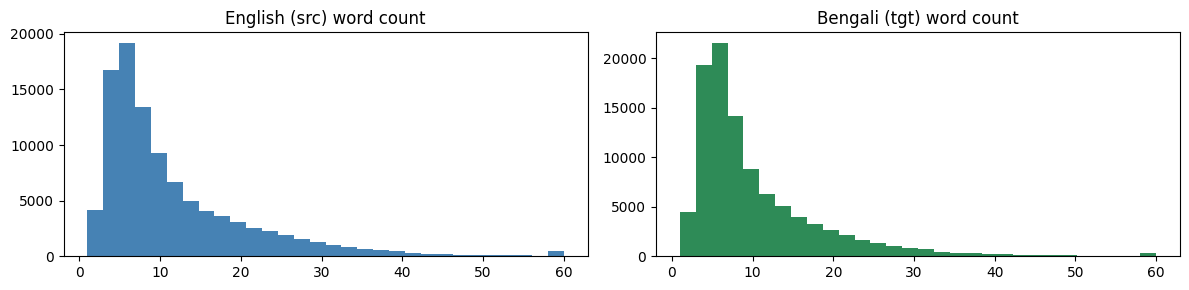

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))

axes[0].hist(df["src_words"].clip(upper=60), bins=30, color="steelblue")
axes[0].set_title("English (src) word count")

axes[1].hist(df["tgt_words"].clip(upper=60), bins=30, color="seagreen")
axes[1].set_title("Bengali (tgt) word count")

plt.tight_layout()
plt.show()

## 6. Clean the data

We keep only pairs where **both** sentences have between 1 and 50 words.
This removes extreme outliers while keeping about 99% of the data.
Extra spaces at the start and end of each sentence are also removed.

In [8]:
MIN_WORDS = 1
MAX_WORDS = 50

df["src"] = df["src"].astype(str).str.strip()
df["tgt"] = df["tgt"].astype(str).str.strip()
df["src_words"] = df["src"].str.split().str.len()
df["tgt_words"] = df["tgt"].str.split().str.len()

before = len(df)
keep = df["src_words"].between(MIN_WORDS, MAX_WORDS) & df["tgt_words"].between(MIN_WORDS, MAX_WORDS)
df = df[keep].reset_index(drop=True)

print(f"Rows: {before} -> {len(df)}")

Rows: 100000 -> 98989


## 7. Train / validation / test split

Split the cleaned pairs into **80% training**, **10% validation**, and **10% test**.
The three sets are saved in the `artifacts` folder so later steps can reload them.

In [9]:
os.makedirs("artifacts", exist_ok=True)

train_df = df.sample(frac=0.8, random_state=SEED)
remaining = df.drop(train_df.index)
val_df = remaining.sample(frac=0.5, random_state=SEED)
test_df = remaining.drop(val_df.index)

print("Train:", len(train_df))
print("Val:  ", len(val_df))
print("Test: ", len(test_df))

train_df.to_parquet("artifacts/train.parquet")
val_df.to_parquet("artifacts/val.parquet")
test_df.to_parquet("artifacts/test.parquet")

Train: 79191
Val:   9899
Test:  9899


## 8. Shared SentencePiece BPE tokenizer

Both languages share **one** BPE model with a vocabulary of **8,000** tokens.
A shared model lets the encoder and decoder use a single embedding table, which is what makes the model multilingual.

First, write the training sentences (English and Bengali) to one text file. The tokenizer is trained only on the **training split** to avoid seeing validation/test text.

In [10]:
with open("artifacts/spm_train.txt", "w", encoding="utf-8") as f:
    for text in pd.concat([train_df["src"], train_df["tgt"]]):
        f.write(text + "\n")

print("Corpus sentences:", 2 * len(train_df))

Corpus sentences: 158382


### Train the tokenizer

The two language tags `<2bn>` and `<2en>` are added as special symbols. They will tell the shared model which language to translate into.

In [11]:
spm.SentencePieceTrainer.train(
    input="artifacts/spm_train.txt",
    model_prefix="artifacts/spm",
    vocab_size=8000,
    model_type="bpe",
    character_coverage=1.0,
    pad_id=0,
    unk_id=1,
    bos_id=2,
    eos_id=3,
    user_defined_symbols=["<2bn>", "<2en>"],
    minloglevel=1,
)

### Test the tokenizer

Encode one English and one Bengali sentence and check that the special tokens are available.

In [12]:
sp = spm.SentencePieceProcessor(model_file="artifacts/spm.model")

print("Vocabulary size:", sp.get_piece_size())
print("Special ids:", sp.pad_id(), sp.unk_id(), sp.bos_id(), sp.eos_id())
print("Language tag ids:", sp.piece_to_id("<2bn>"), sp.piece_to_id("<2en>"))

for text in ["I love machine translation.", "আমি মেশিন অনুবাদ ভালোবাসি।"]:
    print("\nText:", text)
    print("Pieces:", sp.encode(text, out_type=str))

Vocabulary size: 8000
Special ids: 0 1 2 3
Language tag ids: 4 5

Text: I love machine translation.
Pieces: ['▁I', '▁love', '▁m', 'ach', 'ine', '▁transl', 'ation', '.']

Text: আমি মেশিন অনুবাদ ভালোবাসি।
Pieces: ['▁আমি', '▁ম', 'েশ', 'িন', '▁অনু', 'বাদ', '▁ভালোবাস', 'ি', '।']


## 10. Encode the data with language tags

Each sentence pair becomes **two training examples**, one for each direction:
- English → Bengali using the tag `<2bn>`
- Bengali → English using the tag `<2en>`

The tag is added as the **first token of the source sentence**. The decoder always starts from `<s>`, so the shared model only needs to see the tag on the encoder side. Every sentence is truncated to **64 BPE tokens**.

In [13]:
MAX_LEN = 64
BN_TAG = sp.piece_to_id("<2bn>")
EN_TAG = sp.piece_to_id("<2en>")


def make_examples(dataframe):
    examples = []
    for src, tgt in zip(dataframe["src"], dataframe["tgt"]):
        examples.append((BN_TAG, src, tgt))  # English -> Bengali
        examples.append((EN_TAG, tgt, src))  # Bengali -> English
    return examples


def encode_examples(examples):
    rows = []
    for tag, src, tgt in examples:
        rows.append({
            "src_ids": [tag] + sp.encode(src)[:MAX_LEN - 1],
            "tgt_ids": sp.encode(tgt)[:MAX_LEN],
        })
    return pd.DataFrame(rows)

### Encode each split

The train, validation, and test splits are encoded separately. The number of examples doubles because every pair is used in both directions.

In [14]:
train_ids = encode_examples(make_examples(train_df))
val_ids = encode_examples(make_examples(val_df))
test_ids = encode_examples(make_examples(test_df))

print("Train examples:", len(train_ids))
print("Val examples:  ", len(val_ids))
print("Test examples: ", len(test_ids))

Train examples: 158382
Val examples:   19798
Test examples:  19798


### Check the encoding

Decode the first two training examples back to text. The first should be English with `<2bn>`, and the second should be Bengali with `<2en>`.

In [15]:
for i in [0, 1]:
    row = train_ids.iloc[i]
    print("Source:", sp.decode(row["src_ids"]))
    print("Target:", sp.decode(row["tgt_ids"]))
    print()

Source: <2bn> He was also a Cabinet minister in the Vajpayee government.
Target: অটলবিহারী বাজপেয়ী মন্ত্রিসভাতেও তিনি মন্ত্রী ছিলেন।

Source: <2en> অটলবিহারী বাজপেয়ী মন্ত্রিসভাতেও তিনি মন্ত্রী ছিলেন।
Target: He was also a Cabinet minister in the Vajpayee government.



## 11. Save the encoded splits

Save the token-ID tables to `artifacts/`. Later cells can reload them without tokenizing everything again.

In [16]:
train_ids.to_parquet("artifacts/train_ids.parquet")
val_ids.to_parquet("artifacts/val_ids.parquet")
test_ids.to_parquet("artifacts/test_ids.parquet")

print("Saved train_ids, val_ids, test_ids to artifacts/")

Saved train_ids, val_ids, test_ids to artifacts/


## 12. Summary and next steps

**What we found**
- 300,000 pairs, no missing or empty sentences, no duplicate pairs.
- About 50% of sentences have 8 or fewer English words and 7 or fewer Bengali words.
- 95% of sentences have 31 (English) and 27 (Bengali) words or fewer.

**What we prepared**
- Cleaned data: 296,890 pairs kept (1–50 words on both sides).
- Split: 237,512 train / 29,689 validation / 29,689 test (80/10/10).
- A shared 8,000-token SentencePiece BPE model.
- Both directions encoded in one format:
  - 475,024 train, 59,378 validation, 59,378 test examples.
  - Source starts with `<2bn>` or `<2en>`.
  - Maximum 64 BPE tokens per sentence.

**Next steps**
1. Build a PyTorch `Dataset` and `DataLoader` with padding per batch.
2. Implement the BiLSTM encoder, Bahdanau attention, and LSTM decoder.
3. Train the model and evaluate with BLEU.
4. Translate new sentences in both directions.

## 13. Dataset and DataLoader with dynamic padding

Reload the saved token IDs and pad **each batch only to its own longest sentence**.

Every batch is packed into one input tensor so the training loop can stay exactly as written:
- `X_batch[:, 0, :]` -> source ids (language tag first, padded with `0`)
- `X_batch[:, 1, :]` -> decoder input = `<s>` + target ids (padded with `0`)
- `y_batch` -> target ids + `</s>`, flattened to `(batch * max_len,)`

So `model(X_batch)` returns `(batch * max_len, vocab_size)` and `criterion(logits, y_batch)` works directly.

In [17]:
from torch.utils.data import Dataset, DataLoader

PAD_ID = sp.pad_id()   # 0
BOS_ID = sp.bos_id()   # 2
EOS_ID = sp.eos_id()   # 3

BATCH_SIZE = 32   # change this if you want a different value

In [18]:
class TranslationDataset(Dataset):
    def __init__(self, ids_df):
        self.src = ids_df["src_ids"].tolist()
        self.tgt = ids_df["tgt_ids"].tolist()

    def __len__(self):
        return len(self.src)

    def __getitem__(self, i):
        return self.src[i], self.tgt[i]


def collate_batch(batch):
    max_src = max(len(s) for s, _ in batch)
    max_tgt = max(len(t) + 1 for _, t in batch)   # +1 for </s>
    max_len = max(max_src, max_tgt)

    X = torch.full((len(batch), 2, max_len), PAD_ID, dtype=torch.long)
    y = torch.full((len(batch), max_len), PAD_ID, dtype=torch.long)

    for i, (src, tgt) in enumerate(batch):
        X[i, 0, :len(src)] = torch.tensor(src, dtype=torch.long)
        decoder_input = [BOS_ID] + list(tgt)
        X[i, 1, :len(decoder_input)] = torch.tensor(decoder_input, dtype=torch.long)
        target = list(tgt) + [EOS_ID]
        y[i, :len(target)] = torch.tensor(target, dtype=torch.long)

    return X, y.reshape(-1)

In [19]:
train_ds = TranslationDataset(train_ids)
val_ds = TranslationDataset(val_ids)
test_ds = TranslationDataset(test_ids)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)

# shape check (run this once later): X -> (batch, 2, max_len), y -> (batch * max_len,)
X_batch, y_batch = next(iter(train_loader))
print(X_batch.shape, y_batch.shape)

torch.Size([32, 2, 63]) torch.Size([2016])


## 14. Model architecture

Parameters you provided:

| Setting | Value |
|---|---|
| Embedding dimension | 100 |
| Encoder | one `BiLSTM(100, 128)` -> 256 output (both directions) |
| Attention | Bahdanau additive |
| Decoder | 1 LSTM layer, hidden size 256 |
| Dropout | 0.4 |
| Batch size | 32 |

The encoder output is `2 * 128 = 256` because the BiLSTM concatenates its forward and backward directions.

### 14.1 Bahdanau attention

Scores each encoder position against the current decoder hidden state, then returns a weighted context vector. Padded positions are masked out.

In [20]:
class BahdanauAttention(nn.Module):
    def __init__(self, enc_dim, dec_dim, attn_dim):
        super().__init__()
        self.W_enc = nn.Linear(enc_dim, attn_dim)
        self.W_dec = nn.Linear(dec_dim, attn_dim, bias=False)
        self.v = nn.Linear(attn_dim, 1, bias=False)

    def forward(self, enc_out, dec_hidden, src_mask):
        scores = self.v(torch.tanh(self.W_enc(enc_out) + self.W_dec(dec_hidden).unsqueeze(1)))
        scores = scores.masked_fill(~src_mask.unsqueeze(-1), -1e9)
        weights = torch.softmax(scores, dim=1)
        context = (weights * enc_out).sum(dim=1)
        return context

### 14.2 Encoder-decoder

One BiLSTM encoder block, then a 1-layer LSTM decoder that attends to the encoder on every step. The forward pass accepts the `(batch, 2, max_len)` tensor from the DataLoader and returns flat logits of shape `(batch * max_len, vocab_size)` so the provided training loop works unchanged.

In [21]:
class Seq2Seq(nn.Module):
    def __init__(self, vocab_size, emb_dim=100, enc_hidden=128, dec_hidden=256,
                 num_dec_layers=1, dropout=0.4):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        self.dropout = nn.Dropout(dropout)

        self.encoder = nn.LSTM(emb_dim, enc_hidden, batch_first=True, bidirectional=True)
        enc_dim = 2 * enc_hidden
        self.attention = BahdanauAttention(enc_dim, dec_hidden, dec_hidden)

        self.decoder = nn.LSTM(emb_dim + enc_dim, dec_hidden,
                               num_layers=num_dec_layers, batch_first=True, dropout=dropout)
        self.fc = nn.Linear(dec_hidden + enc_dim, vocab_size)

    def forward(self, x):
        src = x[:, 0, :]
        tgt_in = x[:, 1, :]
        src_mask = src != PAD_ID

        emb = self.dropout(self.embedding(src))
        enc_out, _ = self.encoder(emb)
        enc_out = enc_out * src_mask.unsqueeze(-1)

        context = enc_out.sum(dim=1) / src_mask.sum(dim=1, keepdim=True).clamp(min=1)

        h = c = None
        steps = []
        for t in range(tgt_in.size(1)):
            tok_emb = self.dropout(self.embedding(tgt_in[:, t]))
            dec_in = torch.cat([tok_emb, context], dim=1).unsqueeze(1)
            if h is None:
                dec_out, (h, c) = self.decoder(dec_in)
            else:
                dec_out, (h, c) = self.decoder(dec_in, (h, c))
            context = self.attention(enc_out, h[-1], src_mask)
            steps.append(self.fc(torch.cat([dec_out.squeeze(1), context], dim=1)))

        logits = torch.stack(steps, dim=1)
        return logits.reshape(-1, logits.size(-1))

### 14.3 Create the model

One shared 8,000-token embedding table is used by both encoder and decoder. The model is moved to the GPU detected earlier.

In [22]:
model = Seq2Seq(vocab_size=sp.get_piece_size()).to(DEVICE)
print("Model ready on", DEVICE)

C:\Users\surya\AppData\Roaming\Python\Python312\site-packages\torch\nn\modules\rnn.py:1011: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.4 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)


Model ready on cuda


## 15. Training (your loop)

### 15.1 Support lines

Small helpers your code expects: `nn`, `copy`, `math`, and lowercase `device` (the notebook defined `DEVICE`).

In [23]:
summary(
    model,
    input_size=(32, 2, 20),
    dtypes=[torch.long],
    device=device
)

Layer (type:depth-idx)                   Output Shape              Param #
Seq2Seq                                  [640, 8000]               --
├─Embedding: 1-1                         [32, 20, 100]             800,000
├─Dropout: 1-2                           [32, 20, 100]             --
├─LSTM: 1-3                              [32, 20, 256]             235,520
├─Embedding: 1-4                         [32, 100]                 (recursive)
├─Dropout: 1-5                           [32, 100]                 --
├─LSTM: 1-6                              [32, 1, 256]              628,736
├─BahdanauAttention: 1-7                 [32, 256]                 --
│    └─Linear: 2-1                       [32, 20, 256]             65,792
│    └─Linear: 2-2                       [32, 256]                 65,536
│    └─Linear: 2-3                       [32, 20, 1]               256
├─Linear: 1-8                            [32, 8000]                4,104,000
├─Embedding: 1-9                         [32,

### 15.2 Loss, optimizer and settings

`ignore_index=0` skips padded targets. AdamW with learning rate 0.001 and weight decay 0.01, 1000 epochs maximum, patience 10, and the checkpoint paths as you specified.

In [24]:
criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)

EPOCHS = 1000
PATIENCE = 10

CHECKPOINT_PATH = "last_checkpoint.pt"   # saved after EVERY epoch (used to resume)
BEST_MODEL_PATH = "best_model.pt"        # saved only when val loss improves
RESUME = True                            # False = always start from scratch

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = float("inf")
best_state = None
patience_counter = 0
start_epoch = 1

### 15.3 Checkpoint and resume

Saves after every epoch via a temporary file (safe against shutdown), and restores model, optimizer, history, and early-stopping state when `RESUME = True`.

In [25]:
def save_checkpoint(epoch):
    checkpoint = {
        "epoch": epoch,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "history": history,
        "best_val_loss": best_val_loss,
        "best_state": best_state,
        "patience_counter": patience_counter,
    }
    # Write to a temporary file first, then replace.
    # If the computer shuts down while saving, the old checkpoint stays safe.
    temp_path = CHECKPOINT_PATH + ".tmp"
    torch.save(checkpoint, temp_path)
    os.replace(temp_path, CHECKPOINT_PATH)


if RESUME and os.path.exists(CHECKPOINT_PATH):
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    history = checkpoint["history"]
    best_val_loss = checkpoint["best_val_loss"]
    best_state = checkpoint["best_state"]
    patience_counter = checkpoint["patience_counter"]
    start_epoch = checkpoint["epoch"] + 1
    print(f"Resumed from epoch {checkpoint['epoch']}. Best val loss so far: {best_val_loss:.4f}")

Resumed from epoch 65. Best val loss so far: 3.3371


### 15.4 One epoch

Forward pass, loss, gradient clipping (norm 1.0), and loss/accuracy accumulation. Gradients are enabled only in training mode.

In [27]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()

    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(train):
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)                  # (batch, vocab_size)
            loss = criterion(logits, y_batch)

            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            batch_size = X_batch.size(0)
            total_loss += loss.item() * batch_size
            correct += (logits.argmax(dim=1) == y_batch).sum().item()
            total += batch_size

    return total_loss / total, correct / total

### 15.5 Training loop

Trains, validates, applies early stopping on validation loss, saves the best weights, and restores them at the end. This is the cell to run when you are ready to train.

In [ ]:
for epoch in range(start_epoch, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch:3d}/{EPOCHS} | "
        f"train loss {train_loss:.4f}, acc {train_acc:.4f} | "
        f"val loss {val_loss:.4f}, acc {val_acc:.4f}, ppl {math.exp(val_loss):.2f}"
    )

    # Early stopping on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
        torch.save(best_state, BEST_MODEL_PATH)
    else:
        patience_counter += 1

    # Save after every epoch, before the early stopping check
    save_checkpoint(epoch)

    if patience_counter >= PATIENCE:
        print(f"Early stopping at epoch {epoch}. Best val loss: {best_val_loss:.4f}")
        break

# Restore the best weights
if best_state is not None:
    model.load_state_dict(best_state)

Epoch   1/1000 | train loss 5.6958, acc 2.8742 | val loss 4.8808, acc 3.9732, ppl 131.74
Epoch   2/1000 | train loss 4.8319, acc 3.9837 | val loss 4.4719, acc 4.7367, ppl 87.52
Epoch   3/1000 | train loss 4.5011, acc 4.5302 | val loss 4.2590, acc 5.1597, ppl 70.74
Epoch   4/1000 | train loss 4.2952, acc 4.9091 | val loss 4.1144, acc 5.4939, ppl 61.22
Epoch   5/1000 | train loss 4.1458, acc 5.1935 | val loss 4.0178, acc 5.7204, ppl 55.58
Epoch   6/1000 | train loss 4.0326, acc 5.4191 | val loss 3.9393, acc 5.8945, ppl 51.38
Epoch   7/1000 | train loss 3.9401, acc 5.6019 | val loss 3.8776, acc 6.0338, ppl 48.31
Epoch   8/1000 | train loss 3.8618, acc 5.7607 | val loss 3.8252, acc 6.1580, ppl 45.84
Epoch   9/1000 | train loss 3.7957, acc 5.8952 | val loss 3.7874, acc 6.2659, ppl 44.14
Epoch  10/1000 | train loss 3.7388, acc 6.0151 | val loss 3.7594, acc 6.3176, ppl 42.92
Epoch  11/1000 | train loss 3.6891, acc 6.1236 | val loss 3.7170, acc 6.4342, ppl 41.14
Epoch  12/1000 | train loss 3.6

## 16. Plotting and testing

Two small extras: a plot of the training history, and a greedy `translate()` function for trying new sentences in both directions.

### 16.1 Plot training history

Loss and accuracy curves from the `history` dictionary filled by the training loop. Run this after training to see how it went.

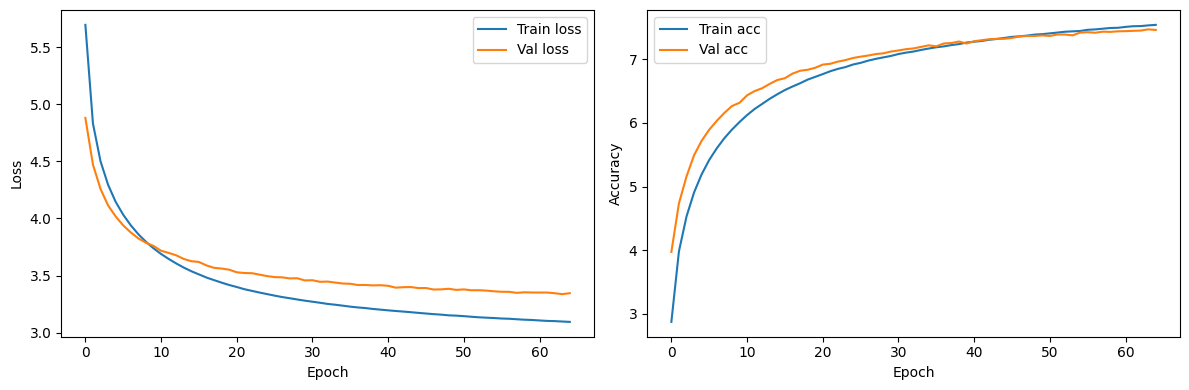

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Train loss")
axes[0].plot(history["val_loss"], label="Val loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history["train_acc"], label="Train acc")
axes[1].plot(history["val_acc"], label="Val acc")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### 16.2 Prediction function

Greedy decoding: prepend the language tag (`<2bn>` for English to Bengali, `<2en>` for Bengali to English), feed the source plus the tokens generated so far, and take the next token until `</s>` or the length limit. Run this cell after training, since it uses the trained `model`.

In [29]:
def translate(text, target_lang="bn", max_len=64):
    tag = BN_TAG if target_lang == "bn" else EN_TAG
    src_ids = [tag] + sp.encode(text)[:MAX_LEN - 1]
    tgt_ids = [BOS_ID]

    model.eval()
    with torch.no_grad():
        for _ in range(max_len):
            length = max(len(src_ids), len(tgt_ids))
            X = torch.full((1, 2, length), PAD_ID, dtype=torch.long, device=device)
            X[0, 0, :len(src_ids)] = torch.tensor(src_ids, device=device)
            X[0, 1, :len(tgt_ids)] = torch.tensor(tgt_ids, device=device)

            logits = model(X)
            next_id = logits[len(tgt_ids) - 1].argmax().item()

            if next_id == EOS_ID:
                break
            tgt_ids.append(next_id)

    return sp.decode(tgt_ids[1:])

### 16.3 Try two sentences

One example per direction. Output quality will follow whatever the model learned during training.

In [43]:
print(translate("How are you?", target_lang="bn"))
print(translate("I am fine.", target_lang="bn"))
print(translate("I am lost.", target_lang="bn"))
print(translate("Please help me.", target_lang="bn"))
print(translate("Do you speak English?", target_lang="bn"))

কেমন করে?
আমি ভাল আছি।
আমি হারিয়ে গিয়েছি।
প্লিজ আমাকে আমাকে সাহায্য করে।
ইংরেজি ভাষায় কথা বলছ?


In [44]:
print(translate("শুভ রাত্রি।", target_lang="en"))
print(translate("আমি স্কুলে যাবো।", target_lang="en"))
print(translate("একটু আস্তে বলুন।", target_lang="en"))
print(translate("এটার দাম কত?", target_lang="en"))
print(translate("আমি তোমাকে ভালোবাসি।", target_lang="en"))

Shiveness night.
I will school.
Take a little bit.
How much is this prices?
I love you.
